In [5]:
import pandas as pd
import numpy as np

In [6]:

# Load the cleaned data
df = pd.read_csv("job_acceptance_after_eda.csv")
print("Shape:", df.shape)
df.head()

Shape: (50000, 26)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,No,0.0,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,No,6.0,Willing,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


## Feature Engineering

We create a few new, easier-to-interpret features from the raw columns. These often help both
human understanding (for dashboards/insights) and model performance.

In [11]:
df['experience_category'].unique()

array(['Junior', 'Fresher', 'Senior'], dtype=object)

In [7]:
# 1. Experience category: Fresher / Junior / Senior
def experience_category(years):
    if years == 0:
        return 'Fresher'
    elif years <= 3:
        return 'Junior'
    else:
        return 'Senior'

df['experience_category'] = df['years_of_experience'].apply(experience_category)

# 2. Academic performance band (average of SSC, HSC, Degree %)
df['academic_avg'] = (df['ssc_percentage'] + df['hsc_percentage'] + df['degree_percentage']) / 3

def academic_band(avg):
    if avg < 60:
        return 'Average'
    elif avg < 75:
        return 'Good'
    else:
        return 'Excellent'

df['academic_band'] = df['academic_avg'].apply(academic_band)

# 3. Skills match level: Low / Medium / High
def skill_level(pct):
    if pct < 50:
        return 'Low'
    elif pct < 75:
        return 'Medium'
    else:
        return 'High'

df['skills_match_level'] = df['skills_match_percentage'].apply(skill_level)

# 4. Interview performance category (average of technical, aptitude, communication)
df['interview_avg_score'] = (df['technical_score'] + df['aptitude_score'] + df['communication_score']) / 3

def interview_category(score):
    if score < 50:
        return 'Weak'
    elif score < 75:
        return 'Average'
    else:
        return 'Strong'

df['interview_performance_category'] = df['interview_avg_score'].apply(interview_category)

# 5. Placement Probability Score (0-100)
# A rule-based, explainable "likelihood to be placed" score built from the factors
# we already know matter most (from our EDA): interview performance, skills match,
# academics, certifications, experience, and competition level.
# NOTE: this is a business heuristic score for quick triage/dashboards - it is
# different from the *model-predicted* probability we'll compute later in
# phase6_ml_modeling.ipynb using the trained ML model.

def experience_score(years):
    # More experience -> higher score, capped at 100
    return min(years * 15, 100)

competition_adjustment = {'Low': 5, 'Medium': 0, 'High': -5}

df['placement_probability_score'] = (
      0.35 * df['interview_avg_score']
    + 0.25 * df['skills_match_percentage']
    + 0.15 * df['academic_avg']
    + 0.10 * df['certifications_count'].clip(upper=10) * 10
    + 0.15 * df['years_of_experience'].apply(experience_score)
    + df['competition_level'].map(competition_adjustment)
).clip(0, 100).round(1)

def probability_band(score):
    if score < 50:
        return 'Low'
    elif score < 75:
        return 'Medium'
    else:
        return 'High'

df['placement_probability_band'] = df['placement_probability_score'].apply(probability_band)

df[['experience_category', 'academic_band', 'skills_match_level',
    'interview_performance_category', 'placement_probability_score',
    'placement_probability_band']].head()


,experience_category,academic_band,skills_match_level,interview_performance_category,placement_probability_score,placement_probability_band
0,Junior,Good,High,Average,60.1,Medium
1,Fresher,Good,Medium,Average,46.5,Low
2,Junior,Excellent,High,Average,63.3,Medium
3,Fresher,Excellent,Medium,Average,59.3,Medium
4,Fresher,Good,High,Average,56.4,Medium


### 5. Validating the Placement Probability Score

Let's sanity-check this heuristic score against the *actual* outcome — candidates who were really Placed should generally have higher scores.

In [17]:
status_colors = {
    'Placed': '#8CBF00',      # Green for Placed
    'Not Placed': '#C83803'   # Red for Not Placed
}

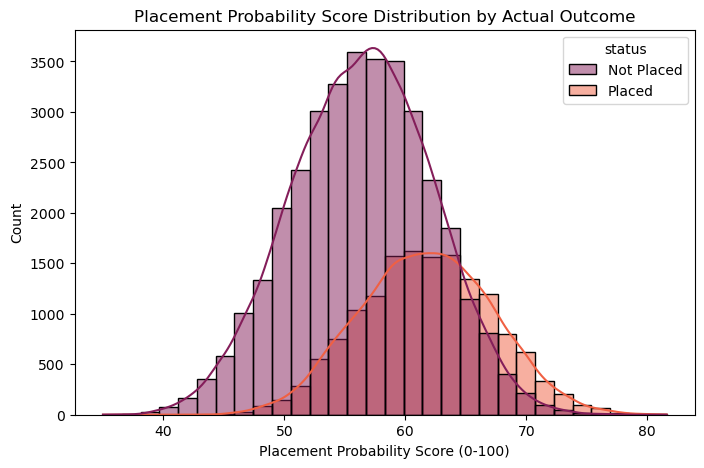

status
Not Placed    56.4
Placed        61.7
Name: placement_probability_score, dtype: float64

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(data=df, x='placement_probability_score', hue='status', kde=True, bins=30,
             palette='rocket')
plt.title("Placement Probability Score Distribution by Actual Outcome")
plt.xlabel("Placement Probability Score (0-100)")
plt.show()

# Quick check: average score for each actual outcome
df.groupby('status')['placement_probability_score'].mean().round(1)

**📌 Insight:** Our rule-based score does a solid job separating the two groups — Placed candidates average ~62/100 vs ~57/100 for Not Placed. It's not a perfect predictor on its own (there's overlap), which is expected since it's a simple weighted formula, not a trained model — but it's a useful quick-triage number for recruiters before the ML model even runs.

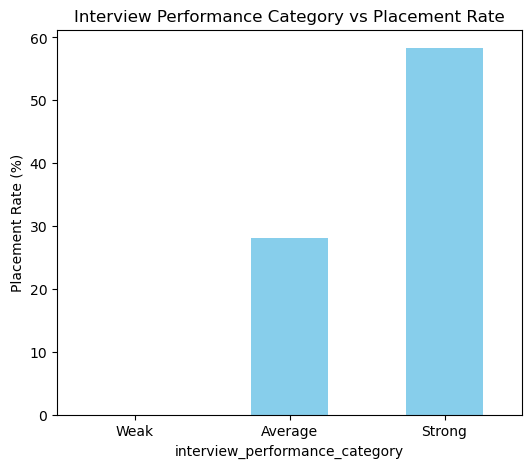

interview_performance_category
Weak        0.000000
Average    28.133059
Strong     58.322020
Name: status, dtype: float64

In [28]:
# Quick visual: does interview_performance_category relate to placement?
rate = df.groupby('interview_performance_category')['status'].apply(lambda x: (x=='Placed').mean()*100)
rate = rate.reindex(['Weak', 'Average', 'Strong'])

plt.figure(figsize=(6,5))
rate.plot(kind='bar', color='skyblue')
plt.ylabel("Placement Rate (%)")
plt.title("Interview Performance Category vs Placement Rate")
plt.xticks(rotation=0)
plt.show()
rate

**Observation:** Candidates with a *Strong* overall interview performance are placed far more often than those rated *Weak* or *Average* — this confirms interview performance is a key driver.

In [10]:
df.to_csv("feature_engineered_data.csv", index=False)
print("Saved feature_engineered_data.csv ✅  Shape:", df.shape)

Saved feature_engineered_data.csv ✅  Shape: (50000, 34)
